<a href="https://colab.research.google.com/github/minxuan0923/AML_Assignment/blob/anne/Set2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import libraries

In [1]:
import pandas as pd
from scipy.io import arff
import requests
from io import StringIO
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, optimizers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

# Load Dataset

In [2]:
URL = (
    "https://raw.githubusercontent.com/"
    "minxuan0923/AML_Assignment/main/data/"
    "UCI_Phishing_Training_Dataset.arff"
)

response = requests.get(URL, timeout=30)
response.raise_for_status()

data, meta = arff.loadarff(StringIO(response.text))

df = pd.DataFrame(data)

for col in df.select_dtypes([object]):
    df[col] = pd.to_numeric(df[col].str.decode('utf-8'))

x_data = df.drop(columns =['Result'])
y_data = df['Result']

# Spliting

In [3]:
X_train, X_test, y_train, y_test = train_test_split(x_data, y_data, random_state = 42, test_size=0.2, stratify=y_data)

# Encoding

In [4]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)

# One-hot-encoding X values
X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

# Convert y values - phishing to "1" and legitimate to "0"
y_train = y_train.replace({-1: 1, 1: 0})
y_test = y_test.replace({-1: 1, 1: 0})

# Evaluation Helper

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

In [6]:
results = {}

def evaluate(name, y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "FN": fn, "FP": fp,
        "FNR": fn / (fn + tp),
    }
    print(pd.Series(results[name]).round(4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=['Legitimate', 'Phishing']).plot(cmap='Blues')
    plt.title(f"Confusion Matrix: {name}"); plt.show()

# Set 2
FCNN with original features

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,529 (25.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8461 - loss: 0.3482 - val_accuracy: 0.9389 - val_loss: 0.1589
Epoch 2/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9234 - loss: 0.1881 - val_accuracy: 0.9491 - val_loss: 0.1420
Epoch 3/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9363 - loss: 0.1571 - val_accuracy: 0.9440 - val_loss: 0.1355
Epoch 4/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9378 - loss: 0.1506 - val_accuracy: 0.9497 - val_loss: 0.1269
Epoch 5/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9409 - loss: 0.1379 - val_accuracy: 0.9474 - val_loss: 0.1262
Epoch 6/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9449 - loss: 0.1358 - val_accuracy: 0.9503 - val_loss: 0.1194
Epoch 7/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9480 - loss: 0.1226 - val_accuracy: 0.9514 - val_loss: 0.1144
Epoch 8/100
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9473 - loss: 0.1201 - val_accu

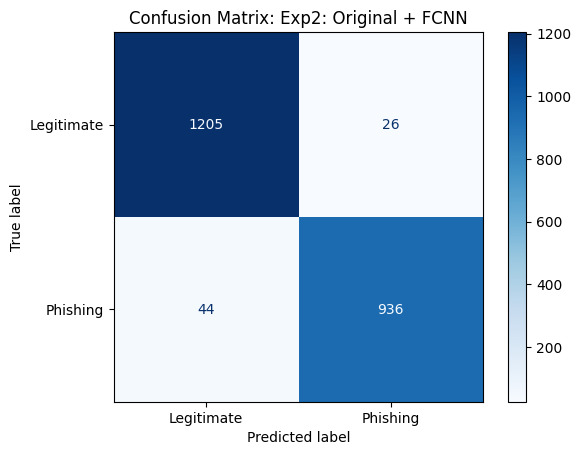

In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_encoded.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = model.fit(X_train_encoded, y_train, validation_split=0.2,
                    epochs=100, batch_size=32, callbacks=[es], verbose=1)

fcnn_prob = model.predict(X_test_encoded).ravel()
fcnn_pred = (fcnn_prob >= 0.5).astype(int)
evaluate("Exp2: Original + FCNN", y_test, fcnn_pred, fcnn_prob)